# Python Sales Data Analysis

Portfolio project using **synthetic** retail data. We explore revenue, profit, regional performance, and monthly trends.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("sales_data.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,region,category,quantity,unit_price,unit_cost
0,ORD-0001,2025-10-10,North,Office Supplies,1,183.97,148.57
1,ORD-0002,2025-02-04,East,Office Supplies,2,390.61,304.03
2,ORD-0003,2025-02-16,North,Office Supplies,5,188.40,124.58
3,ORD-0004,2025-08-24,South,Electronics,7,331.76,226.60
4,ORD-0005,2025-07-22,South,Furniture,1,39.57,31.59


## Data quality and feature engineering

In [2]:
print("Rows:", len(df))
print("Missing values:\n", df.isna().sum())
print("Duplicate orders:", df["order_id"].duplicated().sum())
df["revenue"] = df["quantity"] * df["unit_price"]
df["profit"] = df["quantity"] * (df["unit_price"] - df["unit_cost"])
df[["revenue", "profit"]].describe()

Rows: 240
Missing values:
 order_id      0
order_date    0
region        0
category      0
quantity      0
unit_price    0
unit_cost     0
dtype: int64
Duplicate orders: 0


,revenue,profit
count,240.000000,240.000000
mean,979.736042,306.713458
std,734.417082,258.419890
min,18.570000,7.310000
25%,338.932500,98.760000
50%,857.225000,231.005000
75%,1366.322500,453.622500
max,3113.200000,1246.700000


## Key performance indicators

In [3]:
print(f"Total revenue: ${df.revenue.sum():,.2f}")
print(f"Total profit: ${df.profit.sum():,.2f}")
print(f"Profit margin: {100 * df.profit.sum() / df.revenue.sum():.1f}%")

Total revenue: $235,136.65
Total profit: $73,611.23
Profit margin: 31.3%


## Revenue by region

region
South    73528.18
North    56741.96
East     54397.79
West     50468.72
Name: revenue, dtype: float64


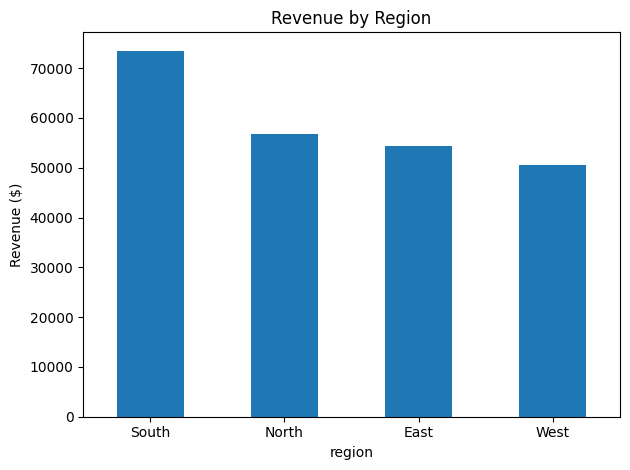

In [4]:
region_sales = df.groupby("region")["revenue"].sum().sort_values(ascending=False)
print(region_sales)
ax = region_sales.plot(kind="bar", title="Revenue by Region", ylabel="Revenue ($)", rot=0)
plt.tight_layout()
plt.show()

## Monthly sales trends

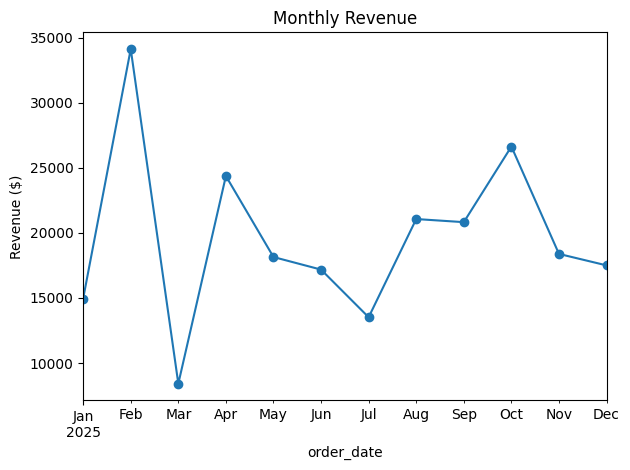

In [5]:
monthly = df.set_index("order_date").resample("MS")["revenue"].sum()
ax = monthly.plot(marker="o", title="Monthly Revenue", ylabel="Revenue ($)")
plt.tight_layout()
plt.show()

## Category performance

In [6]:
print(df.groupby("category")[["revenue", "profit"]].sum().sort_values("revenue", ascending=False))

                  revenue    profit
category                           
Electronics      80667.21  26316.82
Furniture        80037.19  24870.08
Office Supplies  74432.25  22424.33


## Conclusions and Business Recommendations

The following findings are based on **240 simulated retail sales records**. They are provided for educational and portfolio demonstration only, not as evidence of actual business performance.

### 1. Regional performance
The **South** region generated the highest revenue (**$73,528.18**, about **31.3%** of total revenue), while the **West** region generated the lowest (**$50,468.72**). **Recommendation:** Explore the differences in product mix, demand and promotional activity between these regions before deciding where to focus sales initiatives.

### 2. Product category performance
**Electronics** contributed the most revenue (**$80,667.21**) and profit (**$26,316.82**), narrowly ahead of Furniture in revenue (**$80,037.19**). **Recommendation:** Review product-level margins and demand within Electronics and Furniture to guide inventory and marketing decisions.

### 3. Overall profitability
Total revenue was **$235,136.65** and total profit was **$73,611.23**, equivalent to an overall profit margin of approximately **31.3%**. **Recommendation:** Monitor costs and margins by category and region to identify opportunities to improve profitability.

> **Disclaimer:** This dataset is entirely synthetic. All figures, insights and recommendations are **for demonstration only**. These patterns should not be treated as real-world business findings.
